# 001 YOLO11n baseline (Member 2)

Research notebook for the YOLO11n baseline of P14: environment check, dataset handoff sanity, smoke training run, full three-seed baseline, and result summaries.

Setup once from the repository root after `pip install -r requirements.txt` and the dataset preparation commands in the README:

```sh
python -m ipykernel install --user --name cv-project --display-name "Python (cv-project)"
```

Select the cv-project kernel; the repository root is detected automatically. The full baseline trains on the saved split (train 1265 / val 73 / test 78); the test split is never used here.

In [1]:
import json
import platform
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import ultralytics
import yaml
from PIL import Image, ImageDraw

# The repository marker stays findable whether the notebook runs from the root
# or from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'scripts/train_yolo11n.py').exists())

print('python      ', platform.python_version())
print('torch       ', torch.__version__)
print('ultralytics ', ultralytics.__version__)
print('mps         ', torch.backends.mps.is_available())
print('root        ', ROOT)

python       3.11.1
torch        2.14.1
ultralytics  8.4.175
mps          True
root         /Users/pestrovskiy.e/intro-to-CV-Project


## Dataset handoff

Member 1 produced `data/prepared/construction-ppe/dataset.yaml` plus the split manifest. This cell confirms the prepared split matches the documented 1265 / 73 / 78 and the 11 class IDs.

In [2]:
data_yaml = ROOT / 'data/prepared/construction-ppe/dataset.yaml'
assert data_yaml.exists(), 'Run scripts/download_dataset.py and scripts/prepare_dataset.py --apply first'
config = yaml.safe_load(data_yaml.read_text())
print('classes:', config['names'])
images = ROOT / 'data/prepared/construction-ppe/images'
counts = {split: len(list((images / split).iterdir())) for split in ('train', 'val', 'test')}
print('images :', counts)

classes: {0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots', 4: 'goggles', 5: 'none', 6: 'Person', 7: 'no_helmet', 8: 'no_goggle', 9: 'no_gloves', 10: 'no_boots'}
images : {'train': 1265, 'val': 73, 'test': 78}


In [3]:
class_counts = pd.read_csv(ROOT / 'reports/dataset/class_counts.csv')
class_counts[class_counts['split'] != 'all'].pivot_table(
    index=['class_id', 'class_name'], columns='split', values='boxes')

,split,test,train,val
class_id,class_name,,,
0,helmet,161.0,1454.0,119.0
1,gloves,57.0,1351.0,37.0
2,vest,150.0,1376.0,92.0
3,boots,144.0,1413.0,40.0
4,goggles,9.0,501.0,8.0
5,none,51.0,677.0,69.0
6,Person,198.0,1884.0,162.0
7,no_helmet,40.0,400.0,45.0
8,no_goggle,33.0,337.0,41.0


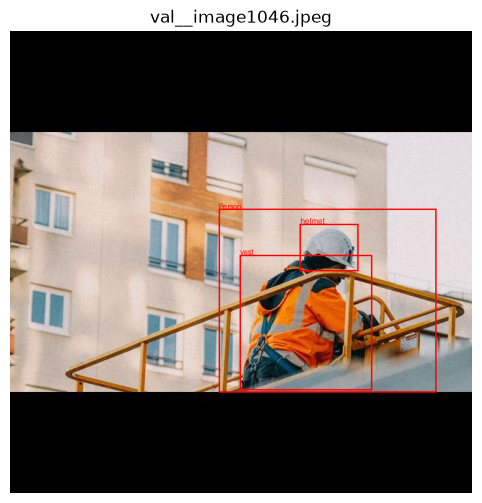

In [4]:
sample = sorted((images / 'val').iterdir())[0]
label_path = images.parent / 'labels' / 'val' / (sample.stem + '.txt')
im = Image.open(sample).convert('RGB')
draw = ImageDraw.Draw(im)
for line in label_path.read_text().splitlines():
    cls, cx, cy, w, h = line.split()
    cx, cy, w, h = map(float, (cx, cy, w, h))
    x0, y0 = (cx - w / 2) * im.width, (cy - h / 2) * im.height
    x1, y1 = (cx + w / 2) * im.width, (cy + h / 2) * im.height
    draw.rectangle((x0, y0, x1, y1), outline='red', width=2)
    draw.text((x0, max(0, y0 - 10)), config['names'][int(cls)], fill='red')
plt.figure(figsize=(8, 6))
plt.imshow(im)
plt.axis('off')
plt.title(sample.name)
plt.show()

## Training protocol

Hyperparameters are fixed by the team report (section 3) and live in `scripts/train_yolo11n.py`; the notebook runs that script so both stay identical.

| Setting | Value |
|---|---|
| Model | yolo11n.pt (COCO pretrained) |
| Epochs / batch / imgsz | 50 / 16 / 640 |
| Optimizer | SGD lr0=0.01 momentum=0.937 wd=0.0005 |
| Schedule | 3 warmup epochs, cosine decay |
| Augmentation | hflip 0.5, scale 0.2, translate 0.1, mild HSV; mosaic off |
| Evaluation | NMS IoU 0.70, conf 0.001, validation split only |
| Seeds | 42, 43, 44; best checkpoint by validation mAP50-95 |

## Smoke run

Two epochs to a scratch directory first, to confirm the environment and the data path before the long run.

In [5]:
subprocess.run([sys.executable, str(ROOT / 'scripts/train_yolo11n.py'), '--seeds', '42', '--epochs', '2',
                '--project', 'reports/training/smoke'], check=True, cwd=ROOT)

=== Training yolo11n seed 42 on mps ===


Ultralytics 8.4.175 🚀 Python-3.11.1 torch-2.14.1 MPS (Apple M4)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/Users/pestrovskiy.e/intro-to-CV-Project/data/prepared/construction-ppe/dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolo11n_seed42, nbs=64, nms=None, opset=None, optimize=False, optimizer=SGD, overlap_mask

Freezing layer 'model.23.dfl.conv.weight'
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 330.0±165.4 MB/s, size: 116.3 KB)
train: Scanning /Users/pestrovskiy.e/intro-to-CV-Project/data/prepared/construction-ppe/labels/train.cache... 1265 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1265/1265 589.5Mit/s 0.0s
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 495.1±381.0 MB/s, size: 152.9 KB)
val: Scanning /Users/pestrovskiy.e/intro-to-CV-Project/data/prepared/construction-ppe/labels/val.cache... 73 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 73/73 76.5Mit/s 0.0s
optimizer: SGD(lr=0.01, momentum=0.937) with parameter groups 81 weight(decay=0.0), 88 weight(decay=0.0005), 87 bias(decay=0.0)


Plotting labels to /Users/pestrovskiy.e/intro-to-CV-Project/reports/training/smoke/yolo11n_seed42/labels.jpg... 


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 40% ━━━━╸─────── 2/5 2.1it/s 0.5s<1.4s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 60% ━━━━━━━───── 3/5 2.9it/s 0.7s<0.7s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.5it/s 1.1s
                   all         73        673      0.747      0.229      0.231     0.0896
                helmet         41        119      0.886      0.437       0.64      0.288
                gloves         16         37        0.6     0.0541      0.169     0.0584
                  vest         42         92       0.53      0.435      0.445      0.186
                 boots         14         40          1          0     0.0273    0.00808
               goggles          6          8          1          0    0.00967    0.00272
                  none         37         69      0.287      0.493      0.253     0.0705
                Person         72        162      0.622      0.765      0.681      0.297
             no_helmet         27         45      0.292      0.333      0.211     0.0466
             no_goggle         25         41          1          0     0.0

Summary written to /Users/pestrovskiy.e/intro-to-CV-Project/reports/training/smoke/yolo11n_summary.json
mAP50-95 per seed: [0.0896]
aggregate: {'mean': 0.0896, 'std': None}


CompletedProcess(args=['/Users/pestrovskiy.e/intro-to-CV-Project/.venv/bin/python', '/Users/pestrovskiy.e/intro-to-CV-Project/scripts/train_yolo11n.py', '--seeds', '42', '--epochs', '2', '--project', 'reports/training/smoke'], returncode=0)

## Full baseline

The three-seed run takes roughly an hour on the M4 laptop; set `FULL_RUN = True` or run `python scripts/train_yolo11n.py` from a terminal (README).

In [6]:
FULL_RUN = False
if FULL_RUN:
    subprocess.run([sys.executable, str(ROOT / 'scripts/train_yolo11n.py')], check=True, cwd=ROOT)

## Results

In [7]:
summary = json.loads((ROOT / 'reports/training/yolo11n_summary.json').read_text())
runs = pd.DataFrame([{'seed': r['seed'], 'train_s': r['train_seconds'], **r['metrics']}
                     for r in summary['runs']])
cols = ['seed', 'train_s', 'mAP50-95', 'mAP50', 'precision', 'recall']
aggregate = pd.DataFrame(summary['aggregate']).T.reset_index(names='metric')
print('device:', summary['device'], '| versions:', summary['versions']['torch'],
      summary['versions']['ultralytics'])
display(runs[cols], aggregate)

device: mps | versions: 2.14.1 8.4.175


,seed,train_s,mAP50-95,mAP50,precision,recall
0,42,3052.2,0.1895,0.4588,0.5967,0.4632
1,43,3090.0,0.2023,0.4955,0.6290,0.4514
2,44,2988.9,0.1934,0.4737,0.5165,0.4836


,metric,mean,std
0,mAP50-95,0.1951,0.0066
1,mAP50,0.4760,0.0185
2,precision,0.5807,0.0579
3,recall,0.4661,0.0163


In [8]:
pd.DataFrame(summary['runs'][0]['metrics']['per_class']).set_index('Class')[
    ['mAP50', 'mAP50-95', 'Box-P', 'Box-R', 'Box-F1']]

,mAP50,mAP50-95,Box-P,Box-R,Box-F1
Class,,,,,
helmet,0.72108,0.33646,0.77684,0.75630,0.76644
gloves,0.52743,0.18614,0.57209,0.54054,0.55587
vest,0.65074,0.34085,0.61082,0.65217,0.63082
boots,0.35446,0.12914,0.49542,0.40000,0.44263
goggles,0.21883,0.05133,0.41008,0.25000,0.31063
none,0.60136,0.25314,0.60765,0.60870,0.60817
Person,0.83943,0.43338,0.79038,0.83791,0.81345
no_helmet,0.51283,0.16194,0.51585,0.55556,0.53497
no_goggle,0.27913,0.07920,0.39379,0.24390,0.30123


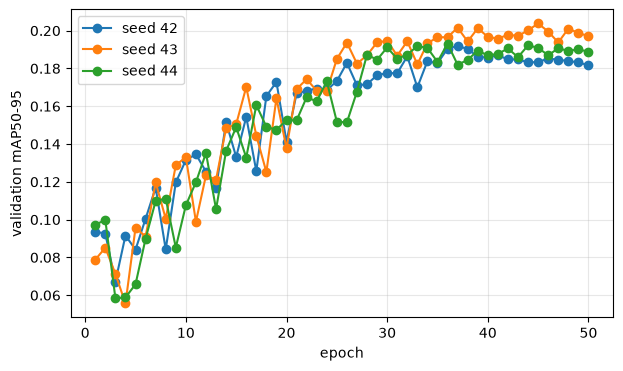

In [9]:
plt.figure(figsize=(7, 4))
for run in summary['runs']:
    curve = pd.read_csv(ROOT / run['run_dir'] / 'results.csv')
    curve.columns = [c.strip() for c in curve.columns]
    plt.plot(curve['epoch'], curve['metrics/mAP50-95(B)'], marker='o', label=f"seed {run['seed']}")
plt.xlabel('epoch')
plt.ylabel('validation mAP50-95')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Notes and limitations

- Training ran on the local device recorded in `yolo11n_summary.json`; a CUDA run may differ slightly.
- `best.pt` is chosen by validation mAP50-95 (Ultralytics 8.4+ fitness rule).
- The validation split is small (73 images) and rare classes (goggles, no_boots) make per-class AP noisy; report mean and std across the three seeds.
- Threshold sweeping, macro-F1 protocol at a fixed confidence, and latency measurements belong to Member 3; this notebook only records the baseline and its training time.
- Checkpoints: `reports/training/yolo11n_seed{seed}/weights/best.pt`; per-run logs next to them.